## assignment 1


## Student Name: Hala Jabareen

## Student Number: 238009

# Step 2.1 — Load packages

In [8]:
%matplotlib inline
#لعرض الاشكال والرسومات تحت الكود مباشرة 

In [ ]:
import pandas as pd        #قراءة البيانات وتنظيمها في جداول والتصفية اذا لزم الامر وتنظيف البيانات اذا فيها ايرور او قيم متكررة 
import numpy as np             #اجراء العمليات الحسابية والتعامل مع المصفوفات 
import matplotlib.pyplot as plt     # لتحويل الارقام الى رسومات ومخططات بيانية 
import seaborn as sns        # انشاء رسومات احصائية تسهل فهم العلاقات والانماط 
from sklearn.preprocessing import LabelEncoder, StandardScaler     #LabelEncoder:تحويل البيانات النصية إلى أرقام ، StandardScaler:توحيد مقاييس البيانات
from sklearn.feature_selection import SelectKBest, f_classif      # SelectKBest: اختيار أفضل الخصائص (Features) ،  f_classif: تقييم الخصائص باستخدام اختبار F
sns.set_style("whitegrid")      #تنسيق شكل الرسم 
plt.rcParams["figure.figsize"] = (10, 5)        #اعدادات الرسم عرض وارتفاع 
pd.set_option("display.width", 100)            # عرض النص في الجدول لحد 100 حرف 
pd.set_option("display.max_columns", 20)      # الحد الاقصى لعدد الاعمدة المعروضة 
print("All packages loaded successfully.")     # طباعة رسالة تؤكد تحميل المكتبات بنجاح 

All packages loaded successfully.


# Step 2.2 — Load the dataset

In [14]:
dataset = pd.read_csv("german_credit_data.csv")   #قراءة ملف البيانات ووضعها في جدول منظم وحفظه في الممتغير 
print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns") #طباعة رسالة تتضمن عدد الصفوف والاعمدة للداتا سيت 

Dataset loaded: 1000 rows, 10 columns


## Step 3 — Exploratory Data Analysis (EDA) 
### 3.1 Descriptive statistics  
###### استخدام المقاييس الاحصائية لتلخيص اهم خصائص البيانات 

In [107]:
dataset.head(15)
#عرض اول 15 صفوف من بيانات الداتا سيت 

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
5,35,male,1,free,NaN,NaN,9055,36,education,good
6,53,male,2,own,quite rich,NaN,2835,24,furniture/equipment,good
7,35,male,3,rent,little,moderate,6948,36,car,good
8,61,male,1,own,rich,NaN,3059,12,radio/TV,good
9,28,male,3,own,little,moderate,5234,30,car,bad


In [108]:
print("Shape (rows, columns):", dataset.shape)
# تحديد عدد الصفوف والاعمدة 

Shape (rows, columns): (1000, 10)


In [109]:
dataset.dtypes
#نوع البيانات الموجودة في كل عمود من الاعمدة 

Age                int64
Sex                  str
Job                int64
Housing              str
SavingAccounts       str
CheckingAccount      str
CreditAmount       int64
Duration           int64
Purpose              str
Risk                 str
dtype: object

In [110]:
dataset.describe()
#ملخص احصائي شامل لكل الاعمدة

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [111]:
dataset.describe(exclude="number")
#يعني استثني الاعمدة الي فيها ارقام وركز ع النصوص في الاحصائيات 

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [112]:
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)
# حساب عدد القيم المفقودة لكل جدول على حدة وطباعتها 

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


In [113]:
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")
# معرفة تكرار البيانات داخل عمود ال risk بالاعداد وبالنسب المئوية 

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


### Figure — missing values by column

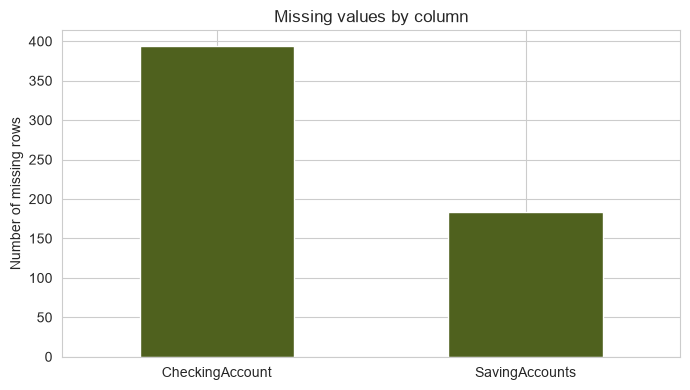

In [114]:
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#4F611E")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
#بحسب عدد القيم المفقودة في كل عمود من أعمدة البيانات، حتى نعرف إذا كان في بيانات غير موجودة
#بحتفظ فقط بالأعمدة الي بتحتوي على قيم مفقودة، وبرتبها من العمود الي في أكبر عدد من القيم المفقودة إلى الأقل
#برسم مخطط أعمدة يوضح عدد القيم المفقودة في كل عمود، عشان نحدد الأعمدة االي بدها معالجة لللبيانات الناقصة فيها

### 3.2 Data visualization

#### Univariate plots
#تحويل الارقام الى رسومات 


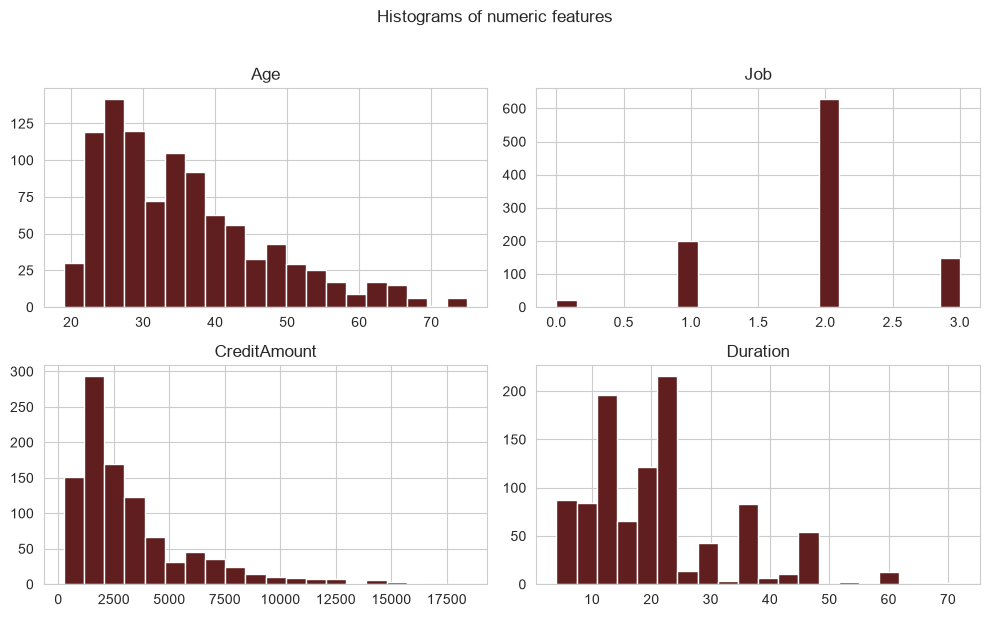

In [115]:
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#611E1E", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()
#بنرسم مخططات لكل عمود فيه أرقام عشان نشوف كيف القيم موزعة وأي قيم بتتكرر أكثر من غيرها
#بنقسم القيم لـ 20 فئة، وبنستخدم لون موحّد وحدود بيضاء عشان تكون المخططات أوضح وأسهل بالقراءة
#بنضيف عنوان للمخططات وبنرتب شكلها، وبعدين بنعرضها عشان نفهم إذا القيم متجمعة بمنطقة معينة أو موزعة على نطاق واسع

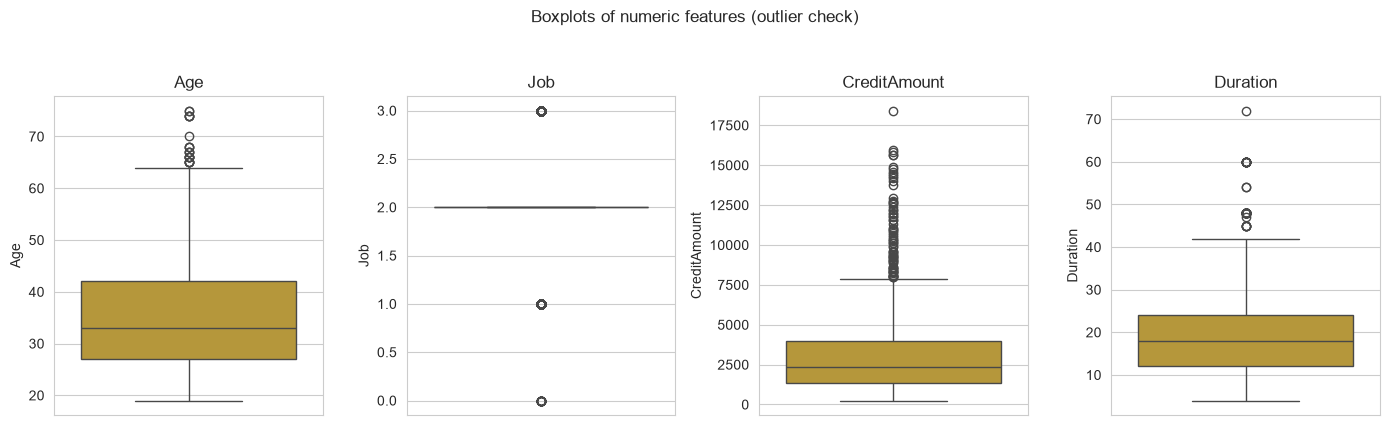

In [96]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()
# بنجهز مكان لعرض مخطط لكل عمود من الأعمدة الرقمية، عشان نقدر نفحص البيانات 
# بنرسم مخطط Boxplot لكل عمود، وبنحط اسم العمود عنوان للمخطط، 
# عشان نشوف توزيع القيم ونحدد إذا في قيم بعيدة عن باقي البيانات (Outliers)
# بنضيف عنوان عام للمخططات وبنرتب شكلها، وبعدين بنعرضها للمقارنة بين الأعمدة ومعرفة إذا فيها قيم غير طبيعية

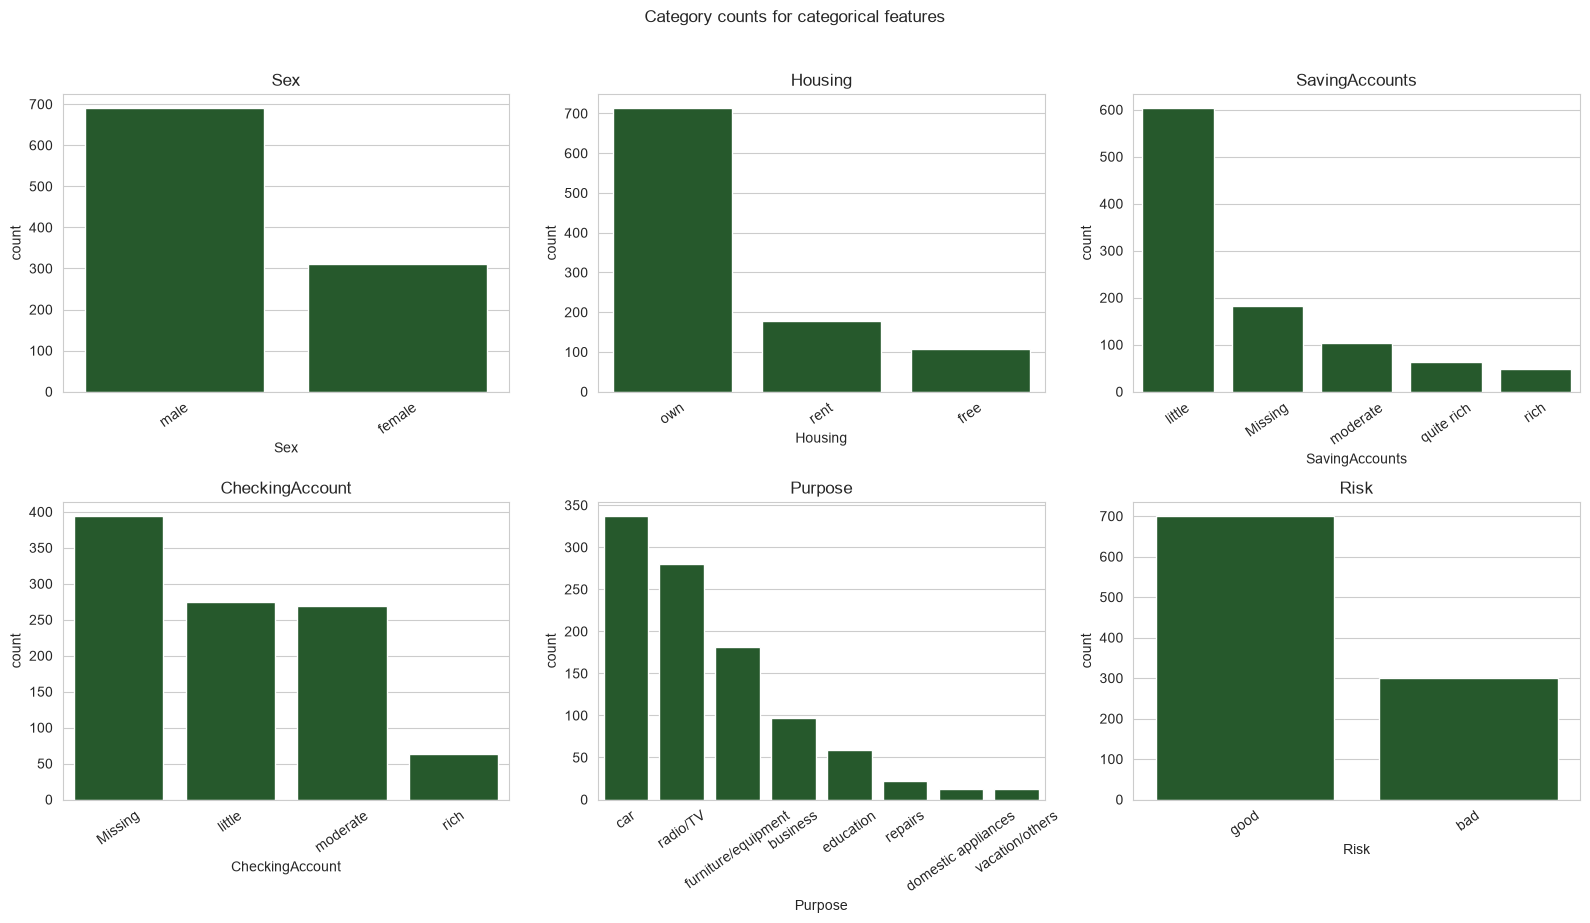

In [97]:
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    col_data = dataset[col].fillna("Missing")
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E6126")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()
# بنحدد الأعمدة اللي فيها بيانات وصفية، زي الجنس ونوع السكن والحسابات البنكية والغرض من القرض ومستوى المخاطرة
# بنجهز 6 مخططات موزعة على صفين وثلاثة أعمدة، وبنعالج القيم الناقصة مؤقتًا عن طريق تسميتها Missing، وبنرتب الفئات حسب عدد تكرارها
# بنرسم مخطط لكل عمود يوضح عدد مرات ظهور كل فئة، وبنضيف اسم العمود عنوانًا للمخطط، وبنميل أسماء الفئات عشان تكون أوضح، وبعدين بنعرض كل المخططات للمقارنة بين الفئات ومعرفة الأكثر تكرارًا

#### Multivariate plots
#الرسومات متعددة المتغيرات


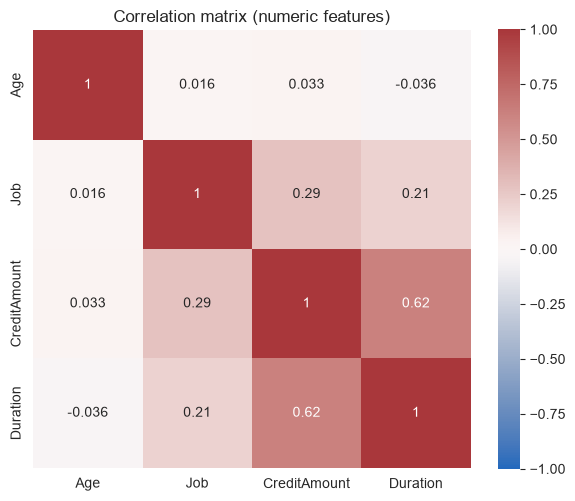

In [98]:
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

# بنحدد حجم الشكل، وبنحسب معامل الارتباط بين الأعمدة الرقمية عشان نعرف إذا في علاقة بينها
# بنرسم خريطة حرارية بتوضح قوة واتجاه العلاقة بين كل عمود والثاني، وبنظهر قيمة الارتباط داخل كل مربع
# بنحدد نطاق القيم من -1 إلى 1، وبنضيف عنوان للمخطط وبنرتب شكله، وبعدين بنعرضه عشان نعرف إذا العلاقة بين المتغيرات موجبة أو سالبة أو ضعيفة

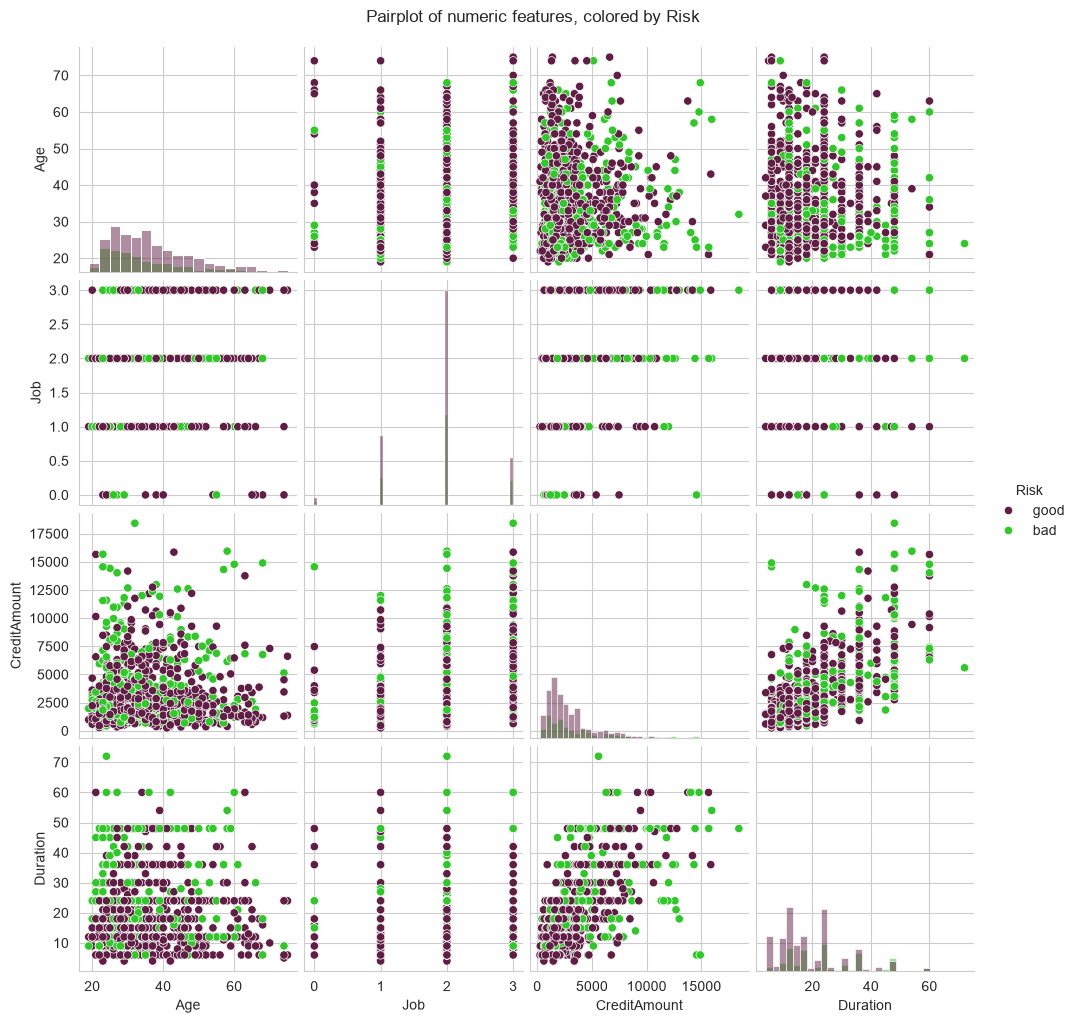

In [99]:
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#611E44", "bad": "#2FC927"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()
# بنرسم مخططات بتجمع بين كل عمود رقمي والعمود الرقمي الثاني، عشان نشوف العلاقة بينهم
# بنستخدم ألوان مختلفة حسب مستوى المخاطرة (Risk)، بحيث اللون الأزرق بيمثل good واللون الذهبي بيمثل bad، عشان نقدر نقارن بين المجموعتين
# بنخلي المخططات القطرية تعرض توزيع القيم لكل عمود، وبنضيف عنوان عام للمخططات، وبعدين بنعرضها عشان نشوف إذا في اختلافات بين أصحاب المخاطرة الجيدة والسيئة


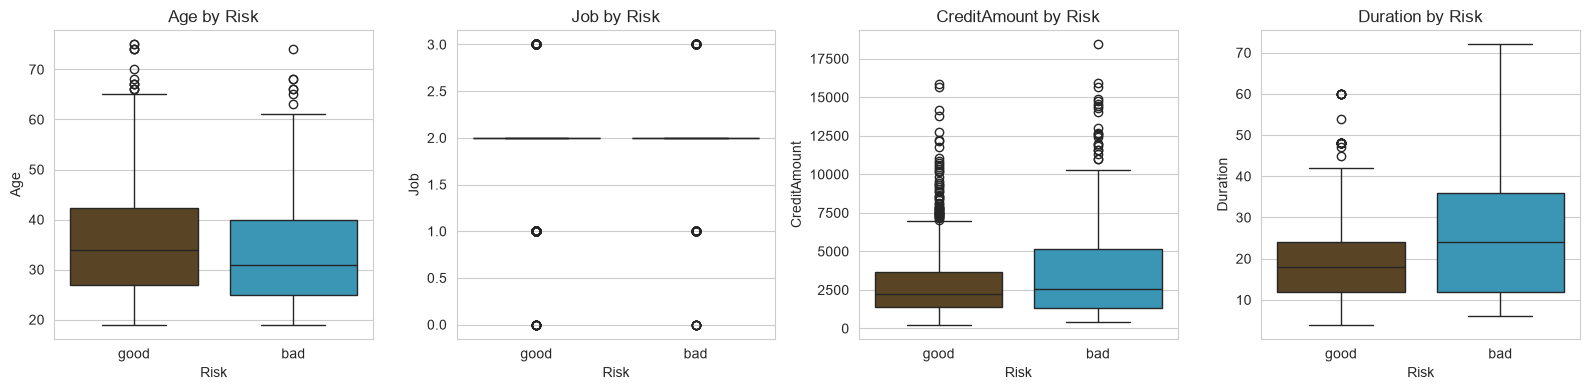

In [100]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#61451E", "bad": "#279EC9"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()
# بنجهز مخطط لكل عمود رقمي عشان نقارن القيم بين فئتي المخاطرة
# بنرسم Boxplot لكل عمود، وبنقسم البيانات حسب Risk، بحيث الأزرق بيمثل good والذهبي بيمثل bad، عشان نشوف الفرق بين المجموعتين
# بنضيف عنوان لكل مخطط وبنرتب شكلها، وبعدين بنعرضها عشان نلاحظ إذا في اختلاف بتوزيع القيم بين أصحاب المخاطرة الجيدة والسيئة


## Step 4 — Data Preparation

### 4.1 Data cleaning — handling missing values

In [101]:
df_clean = dataset.copy()
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")
print("Remaining missing values:\n")
print(df_clean.isna().sum())
# بنعمل نسخة من البيانات الأصلية عشان نعدل عليها بدون ما نغيّر الجدول الأصلي
# بنعبي القيم الناقصة بعمودي SavingAccounts وCheckingAccount بكلمة none، عشان نوضح إن القيمة مش موجودة
# بنطبع عدد القيم الناقصة المتبقية بكل عمود، عشان نتأكد إذا ضل في بيانات ناقصة بعد المعالجة

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


### 4.2 Data transformation — encoding & scaling
#تحويل البيانات الترميز والتحجيم 

In [102]:
df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}  # keep the fitted encoders in case we need to decode values later
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")
    # بنعمل نسخة من البيانات بعد معالجة القيم الناقصة، عشان نجهزها لتحويل البيانات النصية لأرقام
# بنحدد الأعمدة اللي فيها بيانات نصية، زي الجنس والسكن والحسابات البنكية والغرض من القرض ومستوى المخاطرة
# بنستخدم LabelEncoder لتحويل كل فئة نصية لرقم، عشان تصير البيانات مناسبة للتحليل والنماذج، وبنحفظ أداة التحويل لكل عمود عشان نقدر نرجع للأسماء الأصلية إذا احتجنا
# بطبع أسماء الفئات بكل عمود والأرقام اللي انحطت إلها، عشان نعرف كيف تم التحويل


Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [103]:
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]
df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))
# بنستخدم StandardScaler لتوحيد مقاييس البيانات الرقمية، عشان تكون الأعمدة على نفس المقياس
# بنحدد الأعمدة اللي بدنا نعملها Scaling،  العمر والوظيفة ومبلغ القرض ومدة القرض، وبنعمل نسخة من البيانات قبل التعديل
# بنطبق عملية Scaling على الأعمدة المحددة، بحيث يصير متوسط القيم قريب من 0 والانحراف المعياري قريب من 1
# بنطبع أول 3 صفوف قبل وبعد التوحيد، عشان نقارن ونشوف كيف تغيرت القيم


Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


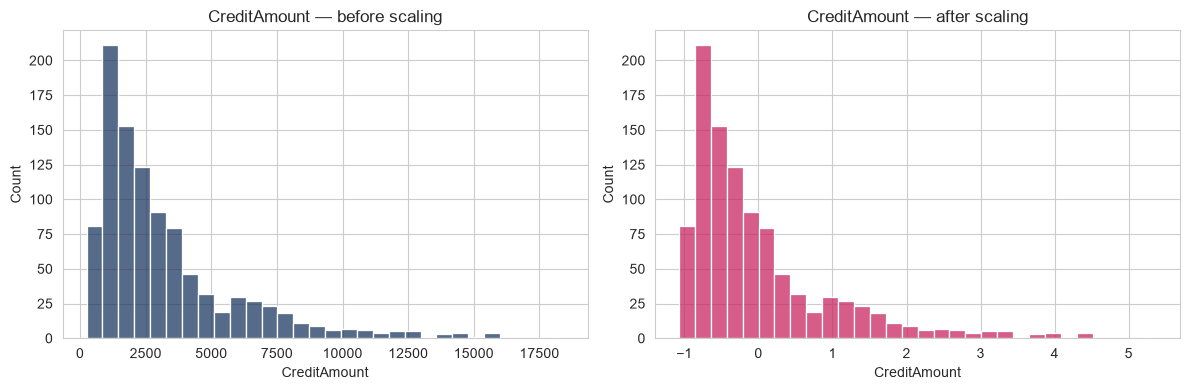

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=30, ax=axes[0], color="#1E3961")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=30, ax=axes[1], color="#C92760")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()
# بنجهز مخططين جنب بعض عشان نقارن توزيع مبالغ القروض قبل وبعد توحيد المقياس
# بنرسم توزيع CreditAmount قبل الـ Scaling باستخدام 30 فئة، وبنعطي المخطط عنوان بيوضح إنها البيانات الأصلية
# بنرسم توزيع نفس العمود بعد الـ Scaling بلون مختلف، وبنضيف عنوان للمخطط، وبعدين بنرتب الشكل وبنعرض المخططين عشان نلاحظ كيف تغيرت قيم القروض بعد التوحيد


### 4.3 Feature selection


In [105]:
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]
selector = SelectKBest(score_func=f_classif, k="all")   # k="all" -> score every feature, keep none/drop none yet
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores
# بنفصل عمود Risk عن باقي البيانات، لأنه هو المتغير اللي بدنا نعرف شو العوامل المرتبطة فيه
# بنستخدم SelectKBest مع اختبار ANOVA عشان نحسب درجة كل عمود، ونشوف قديش قيمه بتختلف بين فئتي المخاطرة good وbad
# بنخلي k="all" عشان نحسب درجة كل الأعمدة بدون ما نحذف أي عمود، وبنرتب النتائج من أعلى درجة لأقل درجة
# بنعرض جدول فيه أسماء الأعمدة ودرجاتها، عشان نعرف أي المتغيرات ممكن تكون أكثر ارتباطًا بمستوى المخاطرة



,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


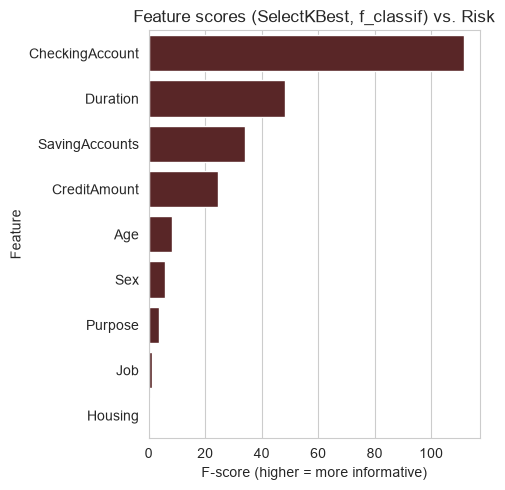

In [106]:
plt.figure(figsize=(5, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#611E1F")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()
# بنرسم مخطط أعمدة يوضح درجات كل feature حسب أهميتها في التمييز بين فئتي Risk
# بنرتب أسماء المتغيرات على المحور العمودي والدرجات على المحور الأفقي
# كلما كانت الدرجة أعلى، كان المتغير أكثر قدرة على التمييز بين فئتي good وbad
# بنعرض الرسم بشكل مرتب عشان نسهل مقارنة المتغيرات مع بعضها

# The End